# **1. Perkenalan Dataset**


Tahap pertama, Anda harus mencari dan menggunakan dataset dengan ketentuan sebagai berikut:

1. **Sumber Dataset**:  
   Dataset yang digunakan adalah **Telco Customer Churn Dataset** yang diperoleh dari repositori publik IBM / Kaggle (`Telco-Customer-Churn.csv`).
2. **Deskripsi Dataset**:  
   Dataset ini berisi informasi demografis pelanggan, layanan telekomunikasi yang didaftarkan, informasi akun/pembayaran, dan status apakah pelanggan berhenti berlangganan (*Churn* = Yes/No) dengan total 7.043 baris dan 21 kolom.

# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning atau deep learning.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler

import warnings
warnings.filterwarnings('ignore')
print('Library berhasil diimpor!')

Library berhasil diimpor!


# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

In [2]:
raw_path = '../telco_churn_raw/telco_churn.csv'
df = pd.read_csv(raw_path)
print('Ukuran Dataset:', df.shape)
display(df.head())

Ukuran Dataset: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

In [4]:
# Mengecek ringkasan statistik dan spasi kosong pada TotalCharges
print('Jumlah nilai kosong awal per kolom:')
print(df.isnull().sum())

empty_total_charges = (df['TotalCharges'] == ' ').sum()
print(f'\nJumlah baris dengan spasi kosong pada TotalCharges: {empty_total_charges}')
print(f'Jumlah baris duplikat: {df.duplicated().sum()}')

Jumlah nilai kosong awal per kolom:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Jumlah baris dengan spasi kosong pada TotalCharges: 11
Jumlah baris duplikat: 0


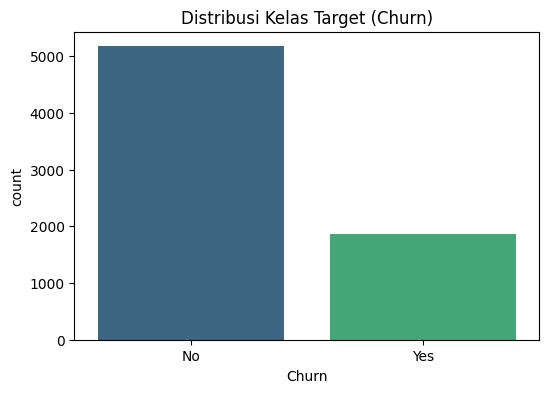

In [5]:
# Visualisasi Distribusi Target (Churn)
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn', palette='viridis')
plt.title('Distribusi Kelas Target (Churn)')
plt.show()

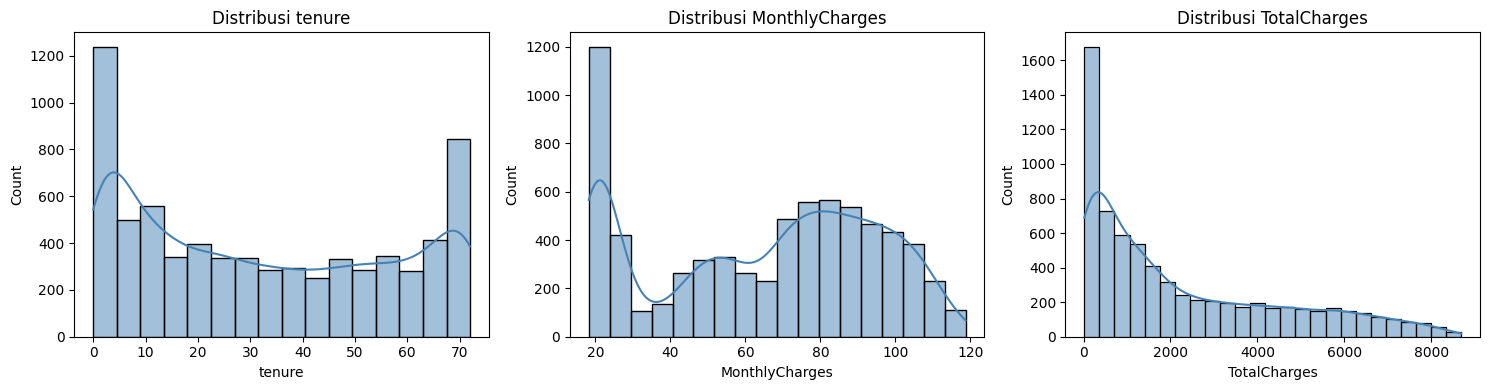

In [6]:
# Visualisasi Distribusi Fitur Numerik
df_eda = df.copy()
df_eda['TotalCharges'] = pd.to_numeric(df_eda['TotalCharges'], errors='coerce')
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(num_cols):
    sns.histplot(df_eda[col].dropna(), kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f'Distribusi {col}')
plt.tight_layout()
plt.show()

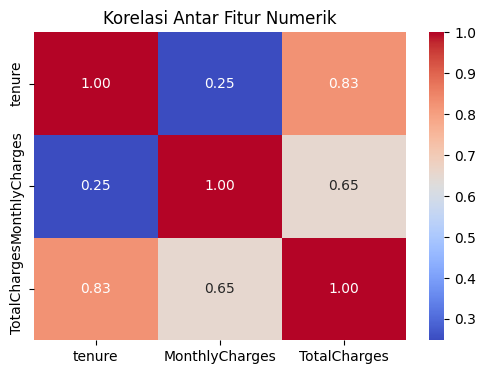

In [7]:
# Correlation Heatmap Fitur Numerik
plt.figure(figsize=(6, 4))
sns.heatmap(df_eda[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Korelasi Antar Fitur Numerik')
plt.show()

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing dilakukan meliputi:
1. Menghapus kolom tidak relevan (`customerID`)
2. Menangani Data Kosong (*Missing Values* pada `TotalCharges`)
3. Menghapus Data Duplikat
4. Deteksi dan Penanganan Outlier (Metode IQR)
5. Encoding Data Kategorikal
6. Standarisasi Fitur Numerik (`StandardScaler`)

In [8]:
# 1. Menghapus kolom customerID
df_clean = df.drop(columns=['customerID']).copy()

# 2. Menangani Missing Values pada TotalCharges
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(df_clean['TotalCharges'].median())

# 3. Menghapus Data Duplikat
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# 4. Penanganan Outlier dengan IQR Capping
for col in num_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    df_clean[col] = np.clip(df_clean[col], Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

# 5. Encoding Data Kategorikal
df_clean['Churn'] = df_clean['Churn'].map({'Yes': 1, 'No': 0})
cat_cols = df_clean.select_dtypes(include=['object']).columns.tolist()
le = LabelEncoder()
for col in cat_cols:
    df_clean[col] = le.fit_transform(df_clean[col].astype(str))

# 6. Standarisasi Fitur Numerik
scaler = StandardScaler()
df_clean[num_cols] = scaler.fit_transform(df_clean[num_cols])

# Simpan hasil preprocessing
os.makedirs('telco_churn_preprocessing', exist_ok=True)
output_file = 'telco_churn_preprocessing/telco_churn_clean.csv'
df_clean.to_csv(output_file, index=False)
print('Preprocessing selesai! Ukuran dataset bersih:', df_clean.shape)
display(df_clean.head())

Preprocessing selesai! Ukuran dataset bersih: (7021, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,-1.282728,0,1,0,0,2,0,0,0,0,0,1,2,-1.164135,-0.997328,0
1,1,0,0,0,0.062387,1,0,0,2,0,2,0,0,0,1,0,3,-0.262811,-0.176347,0
2,1,0,0,0,-1.241967,1,0,0,2,2,0,0,0,0,0,1,3,-0.365914,-0.962760,1
3,1,0,0,0,0.510759,0,1,0,2,0,2,2,0,0,1,0,0,-0.750058,-0.197869,0
4,0,0,0,0,-1.241967,1,0,1,0,0,0,0,0,0,0,1,2,0.194503,-0.943556,1
